# Measured RAW burst to latent Bayer signal


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`frames`，shape `(1, 10, 1024, 1024)`，dtype `<u2`：Original real RAW measurements in ADU; axes batch,time,row,column; complete ten-frame sequence on a fixed native ROI。未知量为1024×1024参考传感器Bayer潜在信号，uint16 ADU。

获取模型：局部运动pullback/曝光增益/颜色采样和shot-read噪声生成十RAW帧。

如何恢复：src.solvers.reconstruct/alignHdrplus及时空频域Wiener patch融合；visualization.run_experiments主动恢复。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell7五图包括原始burst、对齐、融合、参考、关闭对齐/空间/参考控制；8冻结指标。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。第十帧不同曝光ISO且原算法未归一化，是保留模型近似；第十帧不是高质GT；无独立潜在RAW真值。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer a reference-frame latent Bayer signal from a real ten-frame handheld RAW burst. Local motion is a nuisance; the delivered image retains digital offset and quantization rather than absolute radiance.

This active review reconstructs all ten real frames using local multiscale alignment and temporal/spatial Fourier shrinkage. Its primary paper is Monod, Delon and Veit2021, DOI10.5201/ipol.2021.336. The scene is a fixed native1024² central field; no synthetic noise or independent clean target exists. The raw Bayer output retains digital offset and quantization, so it is not absolute radiance or a rendered photograph.

The observation equation is y=b+g[M{x(W(p))}-b]+eta: y is measured ADU, x the latent spatial optical signal, W the local motion pullback, M sensor sampling, eta signal-dependent noise. Variance is lambda_s*y+lambda_r. All acquisition constants and coordinate conventions are stated in the public README. The two method references are separately identified: unmodified2021source75 and the minimally corrected oracle. The latter fixes true2D neighborhood indexing and floating-point RMS; neither is relabeled truth.

Photometric acquisition audit: frames0–8 share ISO1143 and0.0691834390s; frame9 has ISO1551 and0.0999930725s. In the model b is the64ADU black level and g the relative exposure/gain response. The selected original algorithm retains all10 without photometric normalization, a documented approximation. Native reference_frame.txt is0; the last exposure is not treated as truth. The final figure group actively compares first9/all10, per-frame alternate DC weights before1/10 averaging, and the spatial/per-site10-minus9ADU contribution.


## 2. Data

The fixed native 1024-square central region retains all ten uint16 BGGR frames, black 64 ADU and white 1023 ADU. Frames zero through eight share exposure/ISO while frame nine differs; no independent clean target or target-derived calibration exists.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| frames | (1, 10, 1024, 1024) | uint16 | Original real RAW measurements in ADU; axes batch,time,row,column; complete ten-frame sequence on a fixed native ROI |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Burst identifier | 33TJ_20150606_224837_294 | identifier | Measured mobile-camera sequence |
| Exposure count | 10 | frame | All deposited exposures retained in native chronological order |
| Reference frame | 0 | zero-based index | Native first-frame coordinate system |
| Native sensor array | 3120 rows by 4208 columns | pixel | Original deposited DNG dimensions |
| Fixed ROI | rows1048:2072,columns1592:2616 | zero-based half-open pixel | Central1024² region fixed before reconstruction |
| Color filter lattice | BGGR | dimensionless | Upper-left blue, upper-right green, lower-left green, lower-right red |
| Sensor black | 64 on all four sites | ADU | Offset retained during merging |
| Sensor white | 1023 | ADU | Nominal native10-bit white point stored in uint16 |
| ISO, frames0–8 | 1143 | ISO speed | Reference and first nine exposures |
| ISO, frame9 | 1551 | ISO speed | Last exposure has a different gain setting |
| Camera | Motorola Nexus 6 | identifier | Deposited sensor metadata |
| Exposure time, frames0–8 | 297140608/4294967295 (approximately0.0691834390) | s | First nine deposited exposures |
| Exposure time, frame9 | 429466976/4294967295 (approximately0.0999930725) | s | Last deposited exposure; all ten raw frames retained |
| Variance slope lambda_s | 3.55148388 | ADU | Independent author ISO-derived noise model |
| Variance intercept lambda_r | 516.6520187906699 | ADU² | Independent author ISO-derived read-noise model |
| Noise calibration provenance | no NoiseProfile tag; author ISO model | dimensionless | Does not use reconstructed scene truth |
| Coordinates | row down,column right | pixel | Native unrotated sensor orientation |
| Boundaries | symmetric16-pixel extension; finite clipped searches | pixel | Fixed finite detector region, no scene wraparound |
| Absolute pixel pitch/radiometric calibration | unavailable | unavailable | Output uses native pixel coordinates and ADU |

These observations are a fixed native crop of real measurements, without resizing, prealignment or synthetic noise. The noise curve is a documented approximation derived from acquisition ISO rather than a claim of independently measured exact variance.

The selected standard method does not photometrically normalize the different final exposure. It treats disagreement through its reference-guided Fourier weights, so that exposure mismatch remains a documented modeling limitation. Retain all ten observations and the declared digital output convention; do not silently discard or normalize the last exposure.


## 3. Physics

The photometric model is $y=b+g[M\{x\circ W\}-b]+\eta$, where $y$ is observed ADU, $x$ latent spatial signal, $W$ motion pullback, $M$ Bayer sampling, $b$ black offset, $g$ relative exposure/gain response and $\eta$ noise. The selected source algorithm omits explicit per-frame gain normalization; Fourier disagreement shrinkage is an approximation under the audited exposure mismatch.

Ten actual consecutive short-exposure Bayer frames observe one scene. The unknown is the two-dimensional latent Bayer signal in the first frame’s sensor coordinates. A local acquisition model is


$$
y_t(p)=b+g_t[\mathcal M\{x(W_t(p))\}-b]+\eta_t(p),\qquad
\operatorname{Var}(\eta_t(p)\mid y_t)=\lambda_s y_t(p)+\lambda_r.
$$


Here t indexes exposure, p=(row,column) a detector coordinate, x the latent reference-exposure signal, W the local motion pullback, M the sensor color sampling and digitization operator, y the recorded digital signal in ADU, b the sensor black offset, g the relative exposure/gain response, eta the shot/read/model error in ADU, lambda_s the variance slope in ADU and lambda_r its intercept in ADU². The first nine frames share exposure/ISO; the tenth has a longer exposure and higher ISO, so its response differs. The requested spatial image is M{x} on the reference sensor lattice. Motion and interframe disagreement are nuisances, rather than the final requested output. Only even-pixel native displacements are applied to retain Bayer parity. Repeated observations do not provide an independent noise-free truth.


## 4. Method

The local finite pipeline retains four alignment scales, sensor-lattice-preserving shifts, explicit neighborhood quadratic fits and temporal/spatial Fourier shrinkage with overlap-add windows. True 2D neighborhood indexing and floating-point RMS are minimal disclosed source corrections; the unmodified source remains separately compared.

### Local mathematics and independent corrections

The Gaussian pyramid operates on integer-rounded2×2 Bayer averages at fine-to-coarse relative scales1,2,4,4. Reference/alternate tiles overlap by half. Coarse L2 and finest L1 distances select local shifts; coarse subpixel fits minimize an explicitly fitted quadratic over the actual3×3 distance surface. Even native displacements preserve the sensor color lattice. The integer-square overflow diagnostic uses a known[300,400]ADU field, whose correct RMS is sqrt(125000), not the wrapped integer-square result.

For reference Fourier coefficient R, alternate A and variance V, use D=R-A, a=|D|²/(|D|²+cV), and pair A+aD; average the reference plus nine pairs. c=(16²/16)*2*75 for the temporal step. Spatial attenuation multiplies coefficient C by |C|²/(|C|²+f*(16²/16)*0.1*V/10), with f Fourier-bin distance. After inverse FFT, modified cosine windows sum to unity on the retained region. The original reference black offset and uint16 truncation are retained. No optimization convergence is invented for this finite direct pipeline.


## 5. Results

The active path computes nominal and no-alignment/no-spatial/reference-only controls plus frame-count and temporal-strength studies. Retain first-nine/all-ten exposure diagnostics and native per-site ADU differences. Archived scalar metrics are reproducibility checks, not an image cache.

### Actual comparisons

Every panel below is freshly computed: nominal10-frame reconstruction, temporal8, reference-only, no spatial filter, no alignment, and frame-count1/2/5/9/10. The unmodified and corrected upstream arrays are loaded only as labeled independent comparisons. Shared intensity/color limits and identical visual regions expose noise, motion and structure differences without fitting images. The algorithm stops after four fixed scales and finite searches; no neural model or learned weights are used.

Separately archived fresh cleaned-run scalar measurements are a reproducibility record, not a reconstruction cache. The code below compares every archived value with the active recomputation above.


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import run_experiments,make_figures
data=load_data(root/'data/raw_data.npz')
references={}
for key,file in [('corrected','corrected_upstream.npz'),('unmodified','unmodified_upstream.npz')]:
    with np.load(root/'notebooks/reference_outputs'/file,allow_pickle=False) as f: references[key]=f['reconstruction'][0].copy()
start=time.perf_counter()
experiments=run_experiments(data,references)
print(json.dumps({'fresh_runtime_s':time.perf_counter()-start,**experiments['metrics']},indent=2))

{
  "fresh_runtime_s": 27.48187439999674,
  "corrected_upstream_relative_l2": 0.0,
  "unmodified_source75_relative_change": 0.027214062377598963,
  "single_reference_relative_error": 0.12680487363286258,
  "no_alignment_relative_change": 0.06010894401256488,
  "spatial_filter_relative_change": 0.007816531631912201,
  "last_frame_relative_contribution": 0.01485130082610768,
  "last_frame_mean_brightness_change_ADU": 0.08065128326416016,
  "frame1_mean_alternate_DC_weight": 0.9429084405849525,
  "frame9_mean_alternate_DC_weight": 0.443799544465267
}


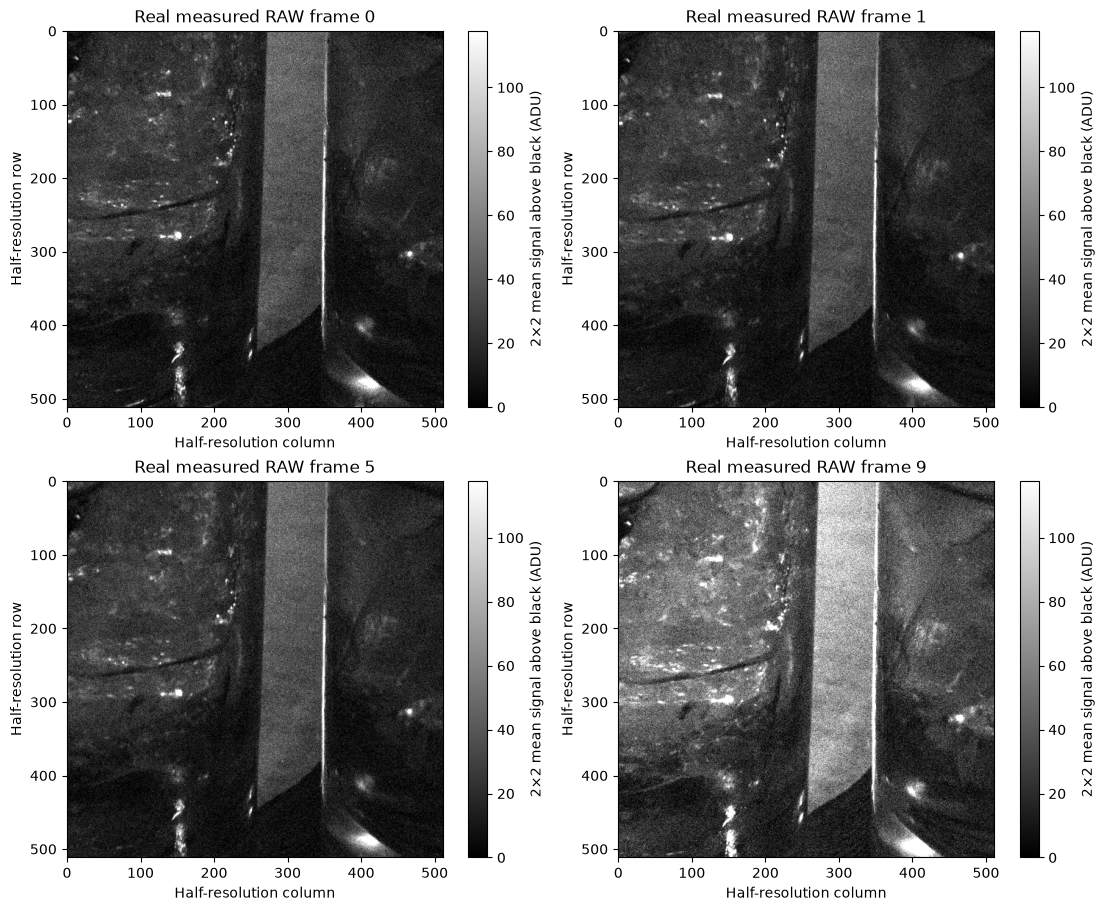

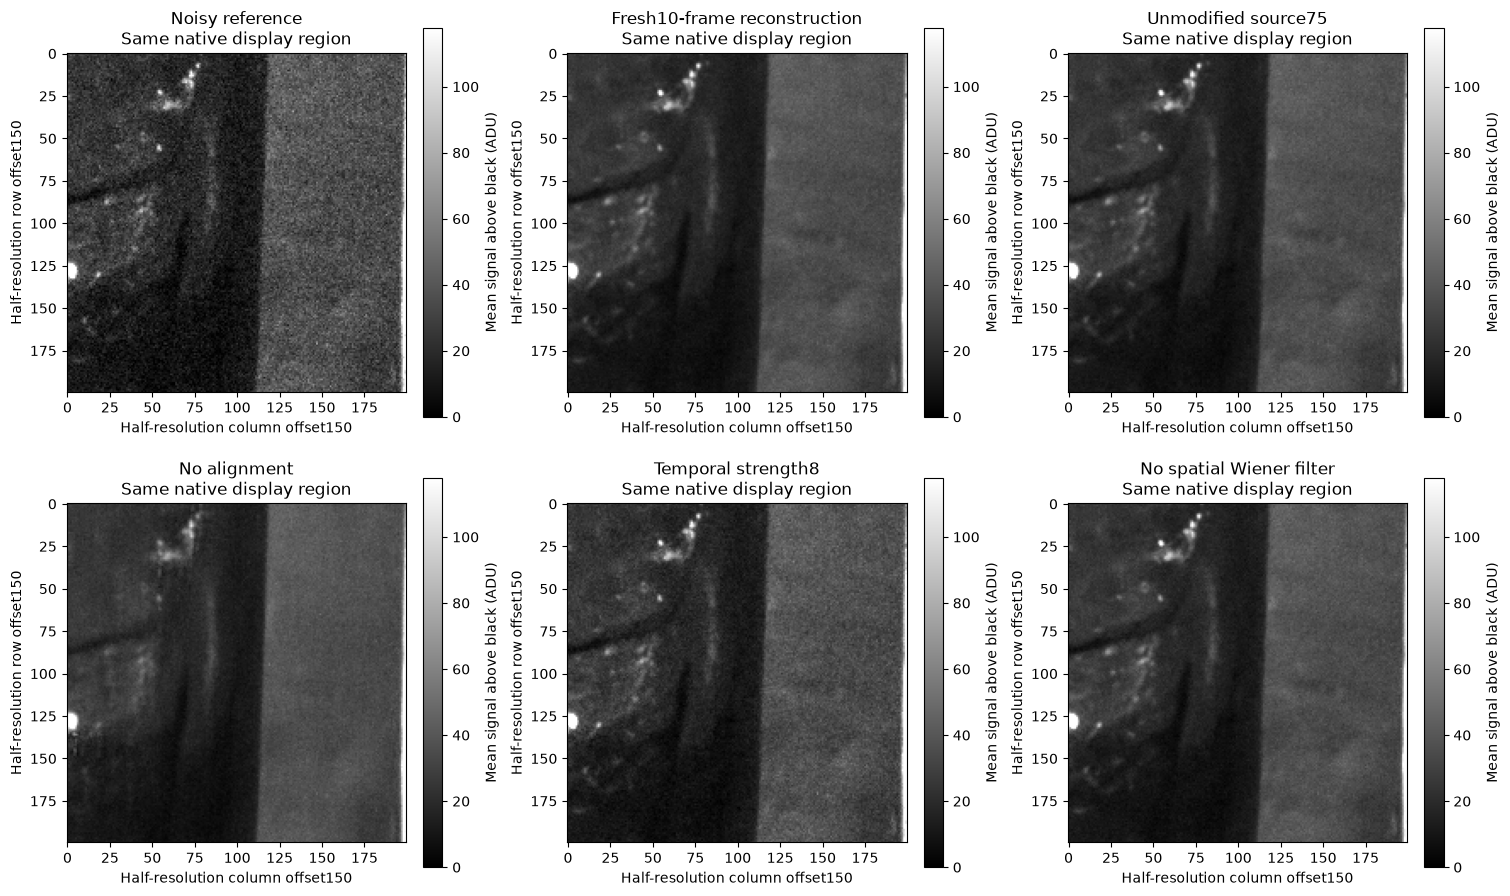

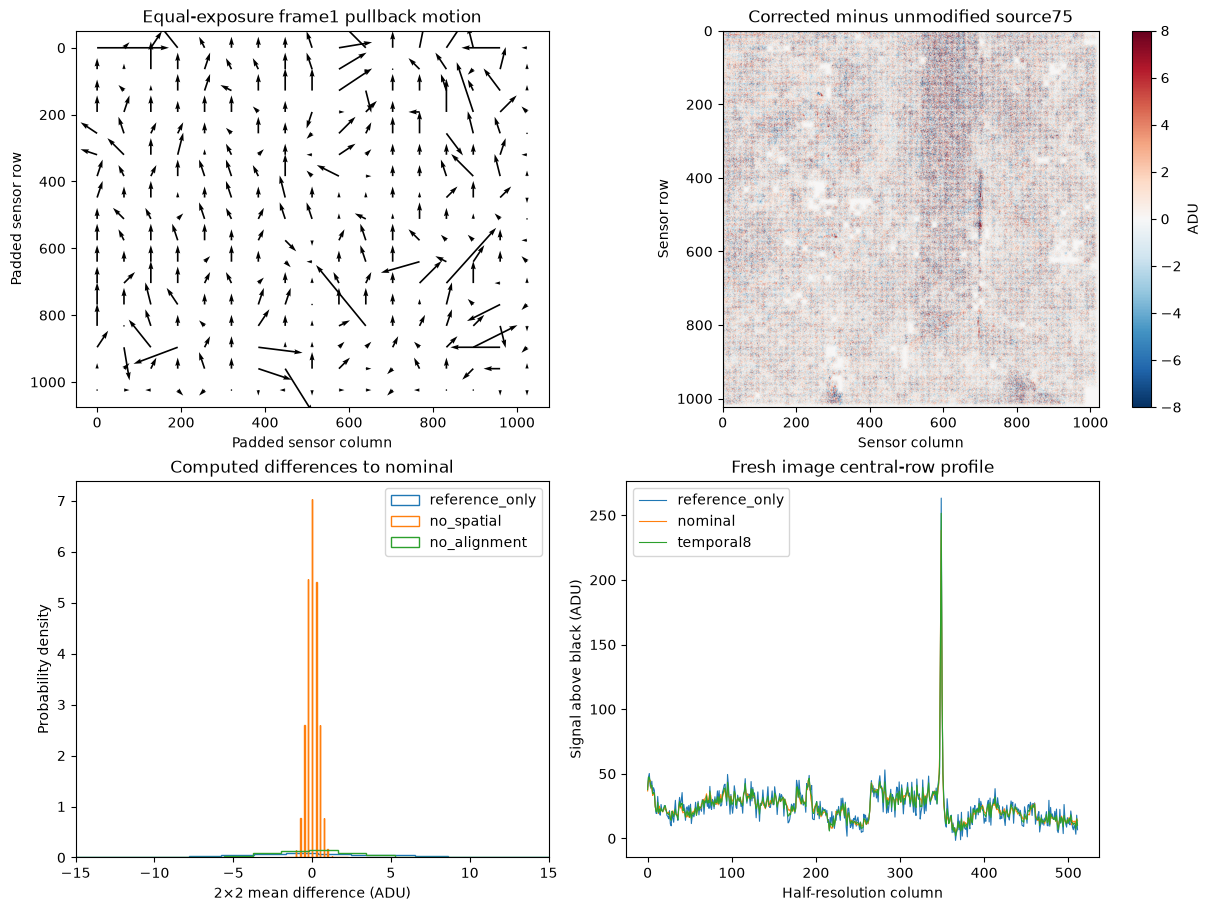

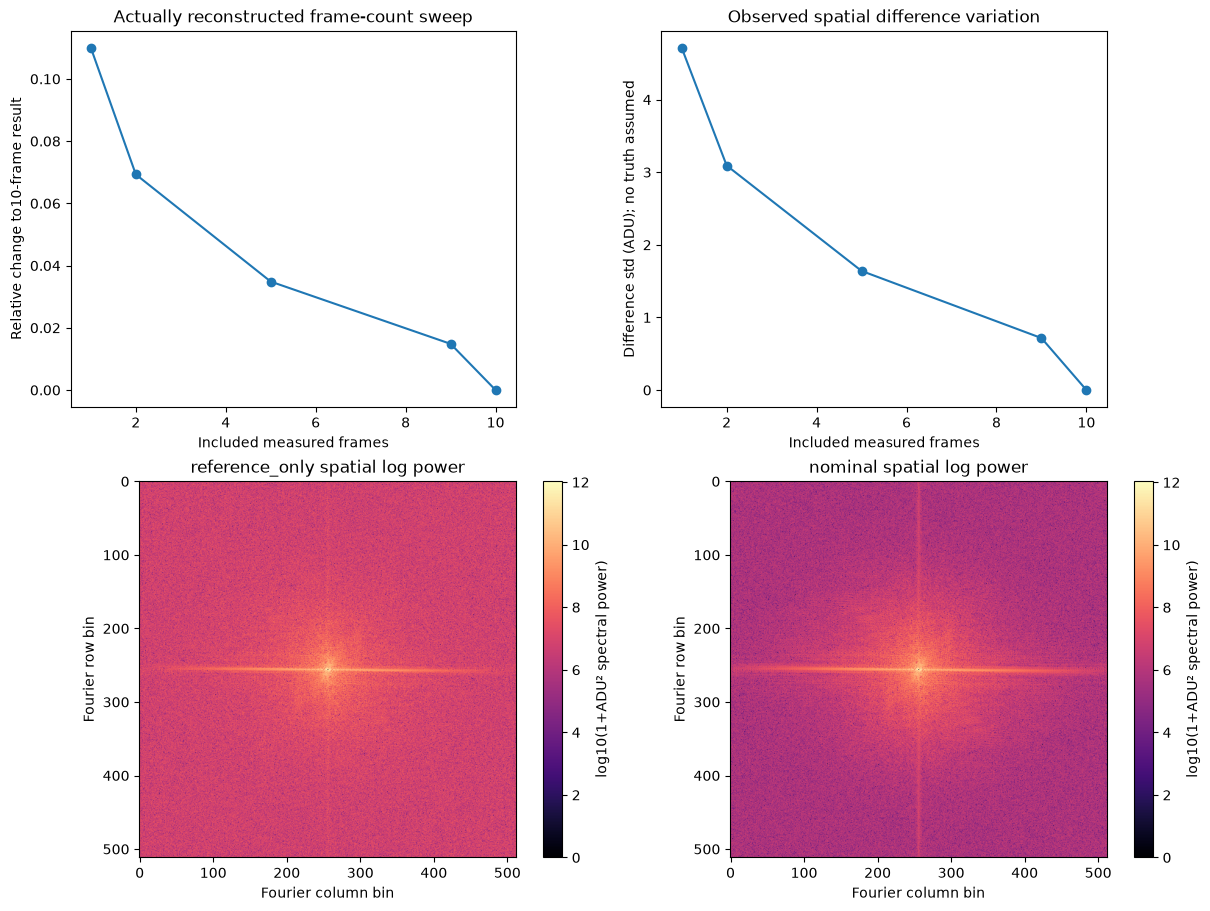

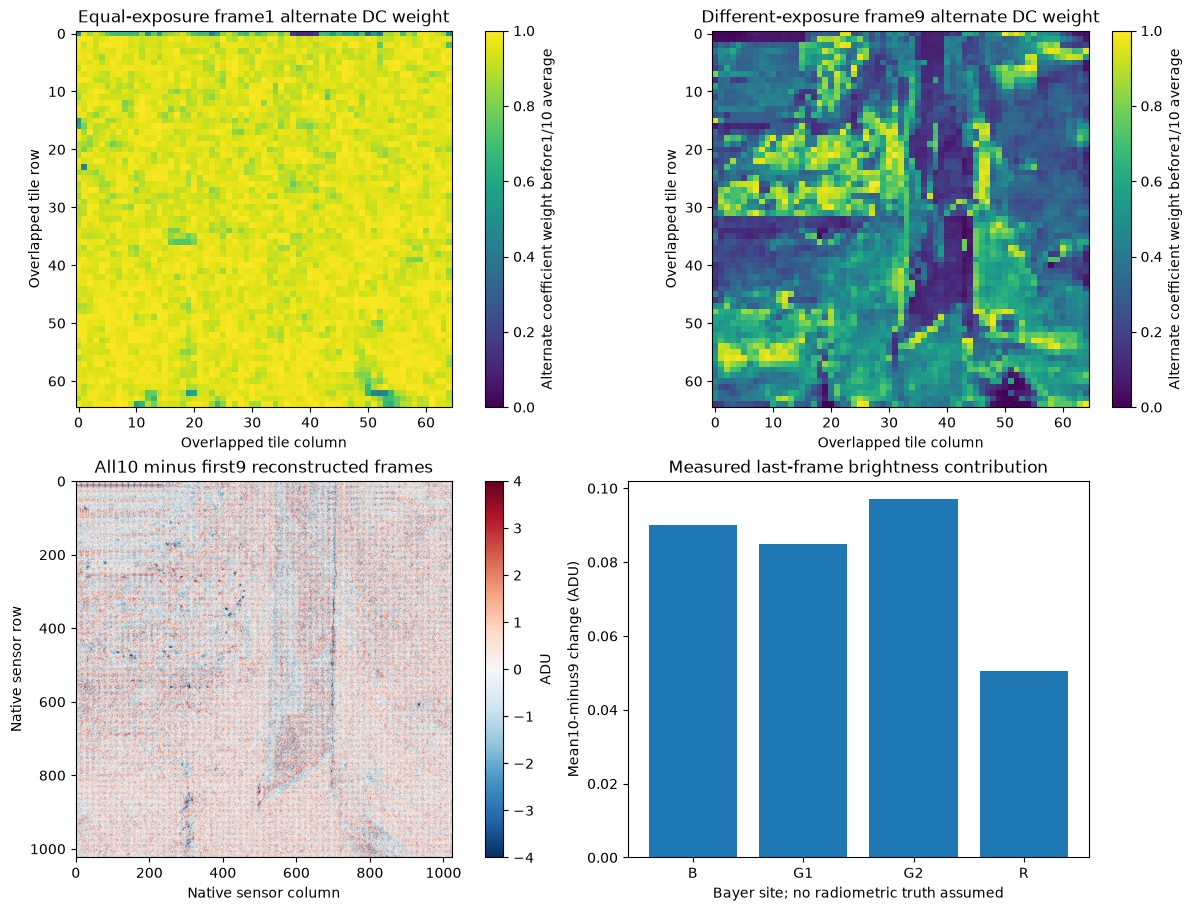

In [2]:
figures=make_figures(data,experiments)
for fig in figures:
    display(fig)
    plt.close(fig)

In [3]:
with np.load(root/'notebooks/reference_outputs/cleaned_metrics.npz',allow_pickle=False) as recorded:
    for key in recorded.files:
        np.testing.assert_allclose(experiments['metrics'][key],recorded[key],rtol=1e-12,atol=1e-12)
    print('Every independent fresh-run scalar measurement agrees with active recomputation.')

Every independent fresh-run scalar measurement agrees with active recomputation.


## 6. Conclusion

The preserved comparisons and window/motion/noise tests support the corrected pipeline. Noise disagreement does not establish true image error, and the changed final exposure plus unnormalized response limit radiometric interpretation; no clean-photo PSNR is fabricated.

### Interpretation

The corrected local result is compared against independent corrected original-stage fixtures and the unmodified source output. Disagreement between noisy frames is not true reconstruction error. No PSNR to an invented clean photograph, anatomical truth or absolute radiometric claim is reported. The scalar/window/motion physics tests provide checks independent of reference agreement.
